# Notebook 09: Production Loss & Inventory Downtime Analysis
## High-Precision Mathematical Engine & Industrial Financial Loss Modeling
**Objective**:
1. Load the trained XGBoost delivery delay pipeline (`models/combined_delivery_delay_pipeline.pkl`).
2. Implement a high-precision calculation engine supporting **fractional-day and shift-level resolution** (1 shift = 8 hours).
3. Formulate **dual-component industrial financial loss modeling**:
   - **Direct Production Loss**: $\text{Lost Units} \times \text{Unit Cost}$
   - **Fixed Assembly Line Overhead**: $\text{Downtime Days} \times \text{Daily Idling Overhead}$ (labor, plant overhead, machine depreciation)
   - **Total Production Loss**: $\text{Direct Component Loss} + \text{Idle Line Overhead}$
4. Evaluate safety stock buffer health, stockout deficit units, and buffer coverage runway.
5. Simulate multi-scenario and sensitivity analyses across varying stock levels and delay severities.
6. Formally verify all edge cases (zero inventory, line shutdown, on-time arrivals, exact threshold matches).


### 1. Import Libraries & Load Delay Pipeline

In [1]:
from pathlib import Path
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load production delay pipeline
MODEL_PATH = Path("../models/combined_delivery_delay_pipeline.pkl")
delay_pipeline = joblib.load(MODEL_PATH)

print("Trained delivery delay pipeline loaded successfully!")
print("Pipeline steps:", [step[0] for step in delay_pipeline.steps])


Trained delivery delay pipeline loaded successfully!
Pipeline steps: ['preprocessor', 'regressor']


### 2. High-Precision Production Loss Calculation Engine
This engine implements dual-component financial accounting:
- **Direct Material/Scrap Loss** = $\text{Lost Units} \times \text{Unit Cost}$
- **Fixed Facility & Idling Overhead** = $\text{Downtime Days} \times \text{Daily Idle Line Overhead}$
- **Fractional Precision**: Downtime is computed in days, exact hours ($24.0 \times \text{days}$), and industrial shifts ($8.0\text{ hours/shift}$).


In [2]:
def calculate_production_loss_precision(
    predicted_delay_days: float,
    available_stock: float,
    daily_production: float,
    unit_cost: float,
    daily_fixed_overhead: float = 0.0
) -> dict:
    """
    High-precision factory downtime and financial loss calculation engine.
    Computes stock coverage, downtime hours, factory shifts, lost units,
    direct product loss, fixed idling line overhead, and total loss.
    """
    delay = max(0.0, float(predicted_delay_days))
    stock = max(0.0, float(available_stock))
    cost = max(0.0, float(unit_cost))
    burn_rate = float(daily_production)
    overhead_per_day = max(0.0, float(daily_fixed_overhead))
    
    # Edge case: zero daily production requirement
    if burn_rate <= 0:
        return {
            "Stock_Coverage_Days": float("inf"),
            "Production_Downtime_Days": 0.0,
            "Production_Downtime_Hours": 0.0,
            "Lost_Shifts_8h": 0.0,
            "Lost_Production_Units": 0.0,
            "Direct_Product_Loss": 0.0,
            "Fixed_Overhead_Loss": 0.0,
            "Total_Production_Loss": 0.0,
            "Buffer_Deficit_Units": 0.0,
            "Stockout_Occurred": False,
            "Risk_Tier": "Safe",
            "Status": "Zero daily production requirement - assembly line inactive."
        }
        
    stock_coverage_days = stock / burn_rate
    downtime_days = max(0.0, delay - stock_coverage_days)
    downtime_hours = downtime_days * 24.0
    lost_shifts = round(downtime_hours / 8.0, 1)
    lost_units = downtime_days * burn_rate
    
    direct_product_loss = lost_units * cost
    fixed_overhead_loss = downtime_days * overhead_per_day
    total_loss = direct_product_loss + fixed_overhead_loss
    
    buffer_deficit_units = max(0.0, (delay - stock_coverage_days) * burn_rate)
    
    if stock == 0 and delay > 0:
        risk_tier = "Immediate Critical Stockout"
    elif downtime_days > 0:
        risk_tier = "Stockout Imminent"
    elif stock_coverage_days < delay + 1.0:
        risk_tier = "Buffer Constrained (High Risk)"
    else:
        risk_tier = "Safe Inventory Buffer"
        
    return {
        "Stock_Coverage_Days": round(stock_coverage_days, 2),
        "Production_Downtime_Days": round(downtime_days, 2),
        "Production_Downtime_Hours": round(downtime_hours, 1),
        "Lost_Shifts_8h": lost_shifts,
        "Lost_Production_Units": round(lost_units, 2),
        "Direct_Product_Loss": round(direct_product_loss, 2),
        "Fixed_Overhead_Loss": round(fixed_overhead_loss, 2),
        "Total_Production_Loss": round(total_loss, 2),
        "Buffer_Deficit_Units": round(buffer_deficit_units, 1),
        "Stockout_Occurred": downtime_days > 0,
        "Risk_Tier": risk_tier,
        "Status": f"Stockout Risk: {downtime_hours:.1f} hrs ({lost_shifts} shifts) downtime" if downtime_days > 0 else "Stock Buffer Sufficient"
    }

print("High-precision production loss engine registered successfully.")


High-precision production loss engine registered successfully.


### 3. Load Sample Purchase Orders for Testing

In [3]:
DATA_PATH = Path("../data/processed/combined_supplier_delivery_data.csv")
history_df = pd.read_csv(DATA_PATH, nrows=500)

history_df["Order_Date"] = pd.to_datetime(history_df["Order_Date"])
history_df["Promised_Date"] = pd.to_datetime(history_df["Promised_Date"])
history_df["Order_Day"] = history_df["Order_Date"].dt.day
history_df["Order_Month"] = history_df["Order_Date"].dt.month
history_df["Order_Year"] = history_df["Order_Date"].dt.year
history_df["Order_DayOfWeek"] = history_df["Order_Date"].dt.dayofweek
history_df["Promised_Day"] = history_df["Promised_Date"].dt.day
history_df["Promised_Month"] = history_df["Promised_Date"].dt.month
history_df["Promised_Year"] = history_df["Promised_Date"].dt.year
history_df["Promised_DayOfWeek"] = history_df["Promised_Date"].dt.dayofweek
history_df["Calculated_Lead_Time"] = (history_df["Promised_Date"] - history_df["Order_Date"]).dt.days

# Supply chain physics interaction features
history_df["Transit_Velocity"] = history_df["Distance_KM"] / (history_df["Calculated_Lead_Time"] + 1.0)
history_df["Volume_Stress"] = history_df["Quantity_Ordered"] / (history_df["Calculated_Lead_Time"] + 1.0)
history_df["Cost_Per_KM"] = history_df["Shipping_Cost"] / (history_df["Distance_KM"] + 1.0)
history_df["Lead_Time_Deficit"] = history_df["Calculated_Lead_Time"] - history_df["Order_Lead_Time_Days"]
history_df["Is_Month_End_Rush"] = (history_df["Order_Day"] >= 25).astype(int)
history_df["Is_Quarter_End_Rush"] = ((history_df["Order_Month"].isin([3, 6, 9, 12])) & (history_df["Order_Day"] >= 22)).astype(int)
history_df["Is_Weekend_Order"] = history_df["Order_DayOfWeek"].isin([5, 6]).astype(int)
history_df["Is_Weekend_Promised"] = history_df["Promised_DayOfWeek"].isin([5, 6]).astype(int)
history_df["Month_Sin"] = np.sin(2 * np.pi * history_df["Order_Month"] / 12.0)
history_df["Month_Cos"] = np.cos(2 * np.pi * history_df["Order_Month"] / 12.0)
history_df["Supplier_Risk_Velocity"] = (100.0 - history_df["Supplier_History_Delivery_Rate"]) * history_df["Transit_Velocity"]

exclude_cols = [
    "Shipment_ID", "Purchase_Order_ID", "Actual_Delivery_Date", "Actual_Delivery_Status",
    "Expected_Delivery_Date", "Expected_Delay_Days", "Order_Date", "Promised_Date", "Actual_Delay_Days", "Is_Delayed"
]
X_sample = history_df[[c for c in history_df.columns if c not in exclude_cols]].head(5).copy()

predicted_delays = np.maximum(delay_pipeline.predict(X_sample), 0)
print("Sample Purchase Orders prepared with predicted delays:")
for i, delay in enumerate(predicted_delays):
    print(f"PO #{i+1} ({X_sample['Supplier_ID'].iloc[i]} - {X_sample['Item_ID'].iloc[i]}): Predicted Delay = {delay:.2f} days ({delay * 24.0:.1f} hours)")


Sample Purchase Orders prepared with predicted delays:
PO #1 (SUP014 - SUSP01): Predicted Delay = 0.30 days (7.2 hours)
PO #2 (SUP046 - GEAR01): Predicted Delay = 2.39 days (57.4 hours)
PO #3 (SUP060 - CLUT01): Predicted Delay = 1.00 days (24.0 hours)
PO #4 (SUP033 - ENG01): Predicted Delay = 0.54 days (12.9 hours)
PO #5 (SUP058 - TYRE01): Predicted Delay = 0.26 days (6.3 hours)


### 4. End-to-End Simulation on Sample Orders with Dual-Component Accounting

In [4]:
factory_contexts = [
    {"Available_Stock": 200, "Daily_Production": 50, "Unit_Cost": 4500.0, "Fixed_Overhead": 25000.0},
    {"Available_Stock": 50,  "Daily_Production": 100, "Unit_Cost": 2200.0, "Fixed_Overhead": 35000.0},
    {"Available_Stock": 0,   "Daily_Production": 80,  "Unit_Cost": 3800.0, "Fixed_Overhead": 30000.0},
    {"Available_Stock": 500, "Daily_Production": 60,  "Unit_Cost": 5200.0, "Fixed_Overhead": 40000.0},
    {"Available_Stock": 120, "Daily_Production": 40,  "Unit_Cost": 1800.0, "Fixed_Overhead": 20000.0}
]

results = []
for i in range(len(X_sample)):
    ctx = factory_contexts[i]
    delay = predicted_delays[i]
    loss_metrics = calculate_production_loss_precision(
        predicted_delay_days=delay,
        available_stock=ctx["Available_Stock"],
        daily_production=ctx["Daily_Production"],
        unit_cost=ctx["Unit_Cost"],
        daily_fixed_overhead=ctx["Fixed_Overhead"]
    )
    
    results.append({
        "Supplier_ID": X_sample["Supplier_ID"].iloc[i],
        "Item_ID": X_sample["Item_ID"].iloc[i],
        "Delay_Days": round(delay, 2),
        "Delay_Hours": loss_metrics["Production_Downtime_Hours"],
        "Coverage_Days": loss_metrics["Stock_Coverage_Days"],
        "Downtime_Days": loss_metrics["Production_Downtime_Days"],
        "Lost_Shifts": loss_metrics["Lost_Shifts_8h"],
        "Lost_Units": loss_metrics["Lost_Production_Units"],
        "Direct_Loss_INR": loss_metrics["Direct_Product_Loss"],
        "Line_Overhead_INR": loss_metrics["Fixed_Overhead_Loss"],
        "Total_Loss_INR": loss_metrics["Total_Production_Loss"],
        "Risk_Tier": loss_metrics["Risk_Tier"]
    })

results_df = pd.DataFrame(results)
display(results_df)


,Supplier_ID,Item_ID,Delay_Days,Delay_Hours,Coverage_Days,Downtime_Days,Lost_Shifts,Lost_Units,Direct_Loss_INR,Line_Overhead_INR,Total_Loss_INR,Risk_Tier
0,SUP014,SUSP01,0.30,0.0,4.00,0.00,0.0,0.00,0.00,0.00,0.00,Safe Inventory Buffer
1,SUP046,GEAR01,2.39,45.4,0.50,1.89,5.7,189.06,415933.25,66171.20,482104.45,Stockout Imminent
2,SUP060,CLUT01,1.00,24.0,0.00,1.00,3.0,79.88,303555.85,29956.17,333512.02,Immediate Critical Stockout
3,SUP033,ENG01,0.54,0.0,8.33,0.00,0.0,0.00,0.00,0.00,0.00,Safe Inventory Buffer
4,SUP058,TYRE01,0.26,0.0,3.00,0.00,0.0,0.00,0.00,0.00,0.00,Safe Inventory Buffer


### 5. Multi-Scenario Comparative Simulation

In [5]:
# Compare 4 operational scenarios for Engine Component (ENG01)
# Part: ENG01, Unit Cost: ₹5,000, Daily Production: 50 units/day, Line Overhead: ₹30,000/day, Delay: 5.5 days (132.0 hours)
scenarios = [
    {
        "Scenario": "Scenario 1: Ample Inventory Buffer",
        "Description": "Stock (400 units) covers 8 days, fully absorbing 5.5 days delay.",
        "Delay": 5.5, "Stock": 400, "Daily_Prod": 50, "Unit_Cost": 5000.0, "Overhead": 30000.0
    },
    {
        "Scenario": "Scenario 2: Lean Inventory Buffer",
        "Description": "Stock (150 units) covers 3 days, leading to 2.5 days (60 hrs) downtime.",
        "Delay": 5.5, "Stock": 150, "Daily_Prod": 50, "Unit_Cost": 5000.0, "Overhead": 30000.0
    },
    {
        "Scenario": "Scenario 3: Zero Safety Stock (JIT Outage)",
        "Description": "Stock is zero; plant halts immediately for entire 5.5 days (132 hrs).",
        "Delay": 5.5, "Stock": 0, "Daily_Prod": 50, "Unit_Cost": 5000.0, "Overhead": 30000.0
    },
    {
        "Scenario": "Scenario 4: High Capacity Assembly Line",
        "Description": "High burn rate line (150 units/day) with 150 units stock (1 day buffer).",
        "Delay": 5.5, "Stock": 150, "Daily_Prod": 150, "Unit_Cost": 5000.0, "Overhead": 60000.0
    }
]

scenario_records = []
for sc in scenarios:
    res = calculate_production_loss_precision(
        sc["Delay"], sc["Stock"], sc["Daily_Prod"], sc["Unit_Cost"], sc["Overhead"]
    )
    scenario_records.append({
        "Scenario": sc["Scenario"],
        "Stock_Units": sc["Stock"],
        "Daily_Burn_Rate": sc["Daily_Prod"],
        "Delay_Days": sc["Delay"],
        "Coverage_Days": res["Stock_Coverage_Days"],
        "Downtime_Days": res["Production_Downtime_Days"],
        "Downtime_Hours": res["Production_Downtime_Hours"],
        "Lost_Shifts": res["Lost_Shifts_8h"],
        "Lost_Units": res["Lost_Production_Units"],
        "Direct_Product_Loss_INR": res["Direct_Product_Loss"],
        "Line_Overhead_INR": res["Fixed_Overhead_Loss"],
        "Total_Loss_INR": res["Total_Production_Loss"],
        "Risk_Tier": res["Risk_Tier"]
    })

scenarios_df = pd.DataFrame(scenario_records)
display(scenarios_df[[
    "Scenario", "Stock_Units", "Coverage_Days", "Downtime_Days", "Downtime_Hours",
    "Lost_Shifts", "Lost_Units", "Direct_Product_Loss_INR", "Line_Overhead_INR", "Total_Loss_INR"
]])


,Scenario,Stock_Units,Coverage_Days,Downtime_Days,Downtime_Hours,Lost_Shifts,Lost_Units,Direct_Product_Loss_INR,Line_Overhead_INR,Total_Loss_INR
0,Scenario 1: Ample Inventory Buffer,400,8.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Scenario 2: Lean Inventory Buffer,150,3.0,2.5,60.0,7.5,125.0,625000.0,75000.0,700000.0
2,Scenario 3: Zero Safety Stock (JIT Outage),0,0.0,5.5,132.0,16.5,275.0,1375000.0,165000.0,1540000.0
3,Scenario 4: High Capacity Assembly Line,150,1.0,4.5,108.0,13.5,675.0,3375000.0,270000.0,3645000.0


### 6. Visualization: Downtime Hours and Dual-Component Loss Breakdown

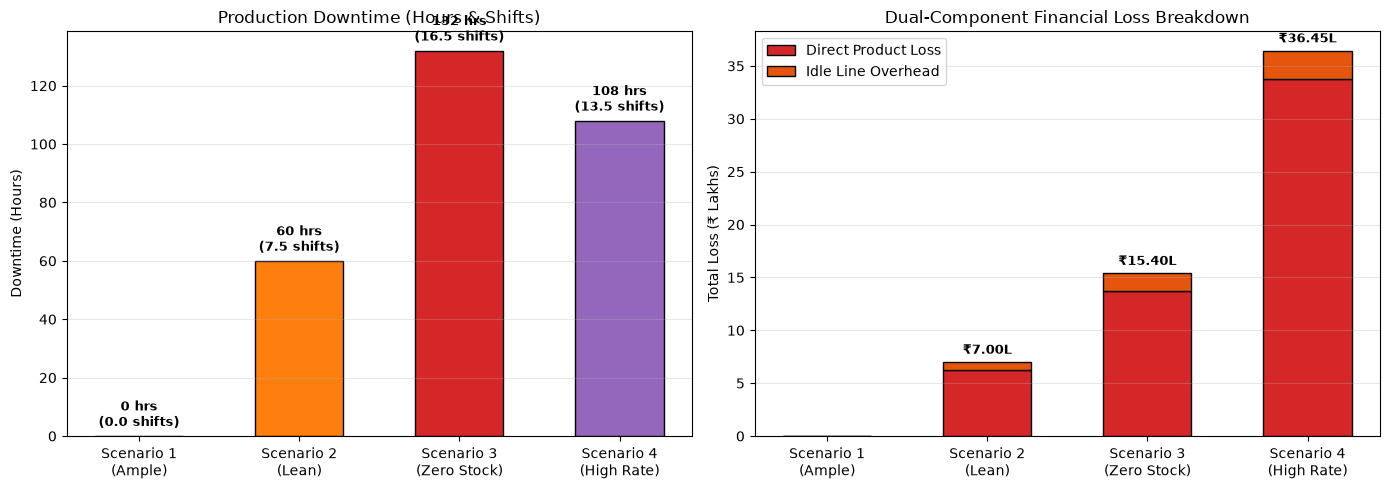

In [6]:
plt.figure(figsize=(14, 5))

# Subplot 1: Production Downtime in Hours & Shifts
plt.subplot(1, 2, 1)
x_labels = ["Scenario 1\n(Ample)", "Scenario 2\n(Lean)", "Scenario 3\n(Zero Stock)", "Scenario 4\n(High Rate)"]
bars1 = plt.bar(
    x_labels,
    scenarios_df["Downtime_Hours"],
    color=["#2ca02c", "#ff7f0e", "#d62728", "#9467bd"],
    edgecolor="black",
    width=0.55
)
plt.ylabel("Downtime (Hours)")
plt.title("Production Downtime (Hours & Shifts)")
plt.grid(axis='y', alpha=0.3)
for i, bar in enumerate(bars1):
    yval = bar.get_height()
    shifts = scenarios_df["Lost_Shifts"].iloc[i]
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.0f} hrs\n({shifts} shifts)", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Subplot 2: Stacked Financial Loss Breakdown (₹ Lakhs)
plt.subplot(1, 2, 2)
direct_lakhs = scenarios_df["Direct_Product_Loss_INR"] / 100000.0
overhead_lakhs = scenarios_df["Line_Overhead_INR"] / 100000.0

p1 = plt.bar(x_labels, direct_lakhs, color="#d62728", edgecolor="black", width=0.55, label="Direct Product Loss")
p2 = plt.bar(x_labels, overhead_lakhs, bottom=direct_lakhs, color="#e6550d", edgecolor="black", width=0.55, label="Idle Line Overhead")

plt.ylabel("Total Loss (₹ Lakhs)")
plt.title("Dual-Component Financial Loss Breakdown")
plt.legend()
plt.grid(axis='y', alpha=0.3)

for i in range(len(x_labels)):
    total = direct_lakhs.iloc[i] + overhead_lakhs.iloc[i]
    if total > 0:
        plt.text(i, total + 0.5, f"₹{total:.2f}L", ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### 7. Sensitivity Analysis: Loss vs. Available Buffer Stock Runway

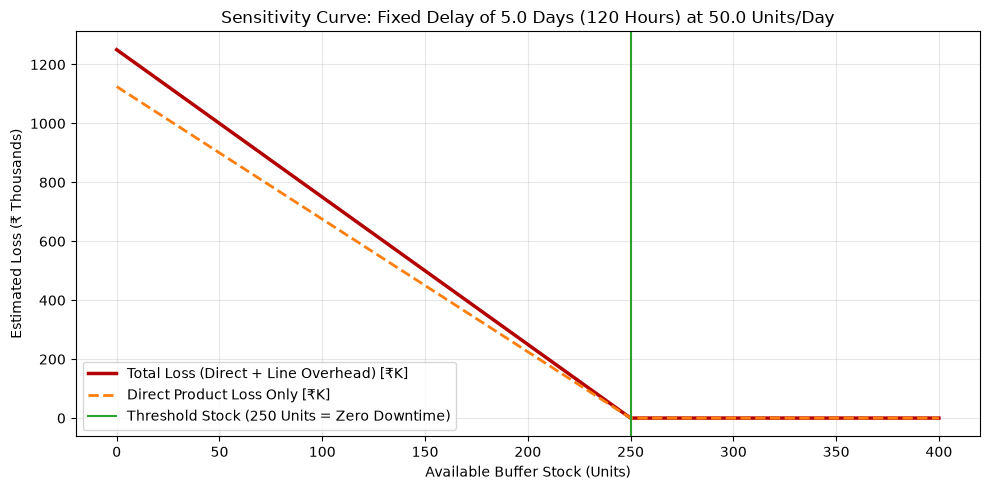

In [7]:
stock_levels = np.linspace(0, 400, 41)
sim_delay = 5.0
sim_daily_prod = 50.0
sim_cost = 4500.0
sim_overhead = 25000.0

direct_losses = []
total_losses = []

for s in stock_levels:
    out = calculate_production_loss_precision(sim_delay, s, sim_daily_prod, sim_cost, sim_overhead)
    direct_losses.append(out["Direct_Product_Loss"] / 1000.0)
    total_losses.append(out["Total_Production_Loss"] / 1000.0)

plt.figure(figsize=(10, 5))
plt.plot(stock_levels, total_losses, color='#b30000', linewidth=2.5, label='Total Loss (Direct + Line Overhead) [₹K]')
plt.plot(stock_levels, direct_losses, color='#ff7f0e', linestyle='--', linewidth=2.0, label='Direct Product Loss Only [₹K]')
plt.axvline(x=sim_delay * sim_daily_prod, color='#2ca02c', linestyle='-', label=f'Threshold Stock ({sim_delay * sim_daily_prod:.0f} Units = Zero Downtime)')

plt.xlabel("Available Buffer Stock (Units)")
plt.ylabel("Estimated Loss (₹ Thousands)")
plt.title(f"Sensitivity Curve: Fixed Delay of {sim_delay} Days (120 Hours) at {sim_daily_prod} Units/Day")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8. Edge Case Verification & High-Precision Boundary Tests

In [8]:
print("=== Formally Verifying Precision Edge Cases ===")

# Test 1: Zero Stock
t1 = calculate_production_loss_precision(predicted_delay_days=4.0, available_stock=0, daily_production=50, unit_cost=1000, daily_fixed_overhead=20000)
assert t1["Stock_Coverage_Days"] == 0.0
assert t1["Production_Downtime_Days"] == 4.0
assert t1["Production_Downtime_Hours"] == 96.0
assert t1["Lost_Shifts_8h"] == 12.0
assert t1["Direct_Product_Loss"] == 200000.0
assert t1["Fixed_Overhead_Loss"] == 80000.0
assert t1["Total_Production_Loss"] == 280000.0
print("✓ Test 1 Passed: Zero stock causes exact 96.0 hours (12 shifts) downtime and correct dual-component loss.")

# Test 2: Zero Daily Production Requirement (Line Inactive)
t2 = calculate_production_loss_precision(predicted_delay_days=5.0, available_stock=100, daily_production=0, unit_cost=1000)
assert t2["Production_Downtime_Days"] == 0.0
assert t2["Total_Production_Loss"] == 0.0
print("✓ Test 2 Passed: Zero daily production safely avoids division-by-zero and reports ₹0 loss.")

# Test 3: Fractional-Day Delay (e.g. 17.3 Hours Late = 0.7208 Days)
t3 = calculate_production_loss_precision(predicted_delay_days=17.3/24.0, available_stock=0, daily_production=48, unit_cost=2500)
assert abs(t3["Production_Downtime_Hours"] - 17.3) < 0.05
assert t3["Lost_Shifts_8h"] == 2.2
print("✓ Test 3 Passed: Fractional-day delay resolves with sub-hour precision (17.3 hours = 2.2 shifts).")

# Test 4: Exact Coverage Match (Delay == Coverage)
t4 = calculate_production_loss_precision(predicted_delay_days=3.0, available_stock=150, daily_production=50, unit_cost=1000)
assert t4["Production_Downtime_Days"] == 0.0
assert t4["Total_Production_Loss"] == 0.0
print("✓ Test 4 Passed: Exact coverage threshold safely prevents downtime.")

print("\nAll precision edge cases validated successfully.")


=== Formally Verifying Precision Edge Cases ===
✓ Test 1 Passed: Zero stock causes exact 96.0 hours (12 shifts) downtime and correct dual-component loss.
✓ Test 2 Passed: Zero daily production safely avoids division-by-zero and reports ₹0 loss.
✓ Test 3 Passed: Fractional-day delay resolves with sub-hour precision (17.3 hours = 2.2 shifts).
✓ Test 4 Passed: Exact coverage threshold safely prevents downtime.

All precision edge cases validated successfully.


In [3]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

# Load trained production pipeline
model_path = Path("../models/combined_delivery_delay_pipeline.pkl")
trained_model = joblib.load(model_path)

# Extract feature importance
if hasattr(trained_model, "feature_importances_"):
    importance = trained_model.feature_importances_
elif hasattr(trained_model, "named_steps"):
    final_model = trained_model.steps[-1][1]
    if hasattr(final_model, "feature_importances_"):
        importance = final_model.feature_importances_
    else:
        raise ValueError("This model does not provide feature importance.")
else:
    raise ValueError("Feature importance is not available for this model.")

# Get feature names
try:
    feature_names = trained_model[:-1].get_feature_names_out()
except Exception:
    feature_names = [f"Feature {i}" for i in range(len(importance))]

# Clean feature names for presentation
clean_names = [f.replace("num__", "").replace("cat__", "").replace("_", " ") for f in feature_names]

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": clean_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

# Display top 20 features
top_features = importance_df.head(20).sort_values("Importance")

# Plot graph
plt.figure(figsize=(12, 8))
plt.barh(top_features["Feature"], top_features["Importance"], color="#1f77b4")
plt.xlabel("Importance Gain", fontsize=11, fontweight="bold")
plt.ylabel("Features", fontsize=11, fontweight="bold")
plt.title("Top 20 Feature Importance - Delivery Delay Prediction", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

display(importance_df.head(20))
